# 02a. KV Cache 앞 절반: block, block table, slot

`01`은 요청 한 건의 여정을 그리면서 "schedule 안에서 block을 받는다"는 빈칸을 남겼습니다. 이 노트북이 그 빈칸을 채웁니다. `01`에서 따라간 요청 `doc`이 정거장 5(schedule)에서 무엇을 받고, 정거장 6(forward)에서 그것을 어떻게 메모리 주소로 바꾸는지를 번호 하나하나까지 따라갑니다. 끝날 때쯤이면 position 하나를 주었을 때 slot을 종이 위에서 계산하고, 한 step의 배열을 보고 어느 칸이 어느 요청인지 읽을 수 있어야 합니다.

## 학습 목표

- KV가 왜 필요한지 다시 넣어야 할 token 수로 말한다.
- block의 metadata와 값이 분리되어 있다는 것과 그 이유를 설명한다.
- position에서 slot을 손으로 계산하고, block이 연속이 아니어도 되는 이유를 말한다.
- 한 step의 packed 배열(`query_start_loc`, `positions`, `seq_lens`, `slot_mapping`)을 읽는다.
- 쓰기 경로와 읽기 경로가 서로 다른 번호를 쓴다는 것과, padding token이 KV를 망가뜨리지 않는 이유를 설명한다.

## 수업 시간표

| 절 | 내용 | 분 |
|---|---|---:|
| 0 | 지도에서 확대: 정거장 5와 6 | 3 |
| 1 | KV가 왜 필요한가 | 5 |
| 2 | block과 `KVCacheBlock` | 7 |
| 3 | block table과 request의 연결 | 6 |
| 4 | slot 공식 | 8 |
| 5 | packed batch | 7 |
| 6 | 쓰기와 읽기, CUDA graph padding | 5 |
| 7 | 직접 해보기, 확인 질문, 정리 | 4 |

## 호출 규모

모델 호출 0회, 유료 API 호출 0회, 키와 GPU가 필요 없습니다. 코드 셀은 네트워크를 쓰지 않고 `vllm`과 `torch`를 import하지 않습니다. 코드 셀이 쓰는 `vllm_lab`에 대해 먼저 밝혀 둡니다. 이것은 vLLM이 아니라 수업용 모델입니다. 코드 설명은 vLLM v0.32.0(커밋 `5df63a7`)의 소스를 읽은 결과입니다. 수업 서버는 다른 빌드이므로(R-01) 이 노트북의 설명을 "수업 서버가 이렇게 동작한다"로 읽지 마세요.

In [1]:
import json

import numpy as np

from vllm_lab import DATA_DIR, DEFAULT_BLOCK_SIZE, VLLM_VERSION, kv_math, kv_sim, view

REFERENCE = json.loads((DATA_DIR / "reference_kv.json").read_text(encoding="utf-8"))
print("기준 소스:", VLLM_VERSION, "/ 수업 block 크기:", DEFAULT_BLOCK_SIZE, "/ 실제 클래스 대조 상태:", REFERENCE["status"])

기준 소스: 0.32.0 / 수업 block 크기: 16 / 실제 클래스 대조 상태: ran


## 0. 지도에서 확대: 정거장 5와 6

`01`의 여정 표에서 이 노트북이 확대하는 구간은 두 칸입니다. 정거장 5에서 EngineCore의 scheduler는 이번 step에 계산할 token 수를 정하고 그 token이 들어갈 block을 배정합니다. 정거장 6에서 GPU worker는 받은 block ID로 메모리 주소를 계산하고 forward를 돌며 KV를 쓰고 읽습니다.

이 구간에는 번호가 세 종류 나옵니다. 처음부터 구분해 두면 뒤가 쉬워집니다.

| 번호 | 무엇의 번호인가 | 누가 정하나 | 범위 |
|---|---|---|---|
| position | 요청 안에서 몇 번째 token인가 | 요청 자체 | 요청마다 0부터 |
| block ID | KV 메모리를 나눈 큰 칸 중 어느 칸인가 | scheduler 쪽 `BlockPool` | pool 전체에서 하나 |
| slot | token 하나가 들어가는 작은 칸의 번호 | worker가 계산 | KV cache 전체에서 하나 |

scheduler는 block ID까지만 다룹니다. slot은 worker에서 처음 생깁니다. 이 구분이 절 2, 3, 4의 뼈대입니다.

**주의.** `doc`은 GLM-5.3-Flash에 보내는 요청이지만, 이 노트북의 block과 slot 규칙은 attention 종류가 하나인 경우(group 하나)로 설명합니다. GLM-5.3-Flash는 층 종류가 여럿이라 그대로 대입할 수 없습니다. 그 이야기는 `02b`에서 합니다. `doc`의 54 token도 수업이 정한 길이이고 실제 tokenizer 결과가 아닙니다.

아래 그림은 이 구간의 흐름입니다. 시간이 아니라 순서입니다. 왼쪽 세로줄이 쓰기, 오른쪽으로 내려가는 두 화살표가 읽기입니다. 절 6에서 다시 봅니다.

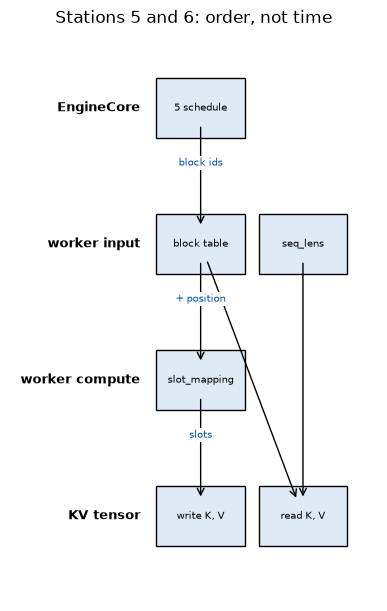

In [2]:
view.lane_diagram(
    {
        "EngineCore": ["5 schedule"],
        "worker input": ["block table", "seq_lens"],
        "worker compute": ["slot_mapping"],
        "KV tensor": ["write K, V", "read K, V"],
    },
    [
        ("5 schedule", "block table", "block ids"),
        ("block table", "slot_mapping", "+ position"),
        ("slot_mapping", "write K, V", "slots"),
        ("block table", "read K, V", ""),
        ("seq_lens", "read K, V", ""),
    ],
    title="Stations 5 and 6: order, not time",
)

**왜 이렇게 설계했나.** scheduler의 주석([vllm/v1/core/sched/scheduler.py:594](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L594))은 scheduler 안에 decode 단계도 prefill 단계도 없다고 적습니다. 요청마다 계산한 token 수(`num_computed_tokens`)가 draft token까지 포함한 전체 token 수(`num_tokens_with_spec`)를 따라잡도록 token을 배정할 뿐이고, 긴 프롬프트를 나누는 일, 캐시 적중, draft token이 모두 이 한 가지 틀 안에 든다고 설명합니다([vllm/v1/core/sched/scheduler.py:601](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L601)). 그래서 block도 "prefill 때 한 번에"가 아니라 계산이 진행되는 만큼 step마다 받습니다(P2-03, P1-02). 예외가 하나 있습니다. DP prefill balancing을 켠 상태에서 step이 throttle되면 scheduler는 `is_prefill_chunk`를 보고 prefill을 미룹니다(코드 읽기, [vllm/v1/core/sched/scheduler.py:634](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L634), [vllm/v1/core/sched/scheduler.py:686](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L686)).

## 1. KV가 왜 필요한가

attention layer는 token 하나를 계산할 때 앞선 token들의 K와 V를 읽습니다. 앞선 token의 K, V를 보관해 두지 않으면 다음 token을 계산할 때마다 문맥 전체를 모델에 다시 넣어 그것을 다시 만들어야 합니다. KV cache는 이미 계산한 token의 K, V를 GPU에 보관해 두고 다음 계산에서 다시 읽게 하는 저장소입니다(P2-01). 그 덕분에 다음 step에는 새 token만 넣으면 됩니다.

**비용을 어디까지 말할 수 있나.** attention 연산량이 문맥 길이에 따라 어떤 식으로 늘어나는지는 소스와 공식 문서에서 확인하지 못했습니다(P2-02(미확인)). 그래서 연산량 공식을 쓰지 않습니다. 대신 확인할 수 있는 것만 셉니다. **모델에 다시 넣어야 할 token 수**입니다. 다른 자료에서 연산량 식을 보았더라도 그 공식은 이 노트북이 근거로 삼는 범위 밖입니다.

**공식 문서.** 공식 문서에는 이 설명이 없습니다.

**코드.** 저장소의 모양은 [vllm/v1/attention/backends/flash_attn.py:1197](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/flash_attn.py#L1197)의 docstring에, 새 K, V를 `slot_mapping`으로 기록하는 호출은 [vllm/v1/attention/backends/flash_attn.py:1452](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/flash_attn.py#L1452)에 있습니다. 이 두 줄은 절 2와 절 6에서 다시 봅니다.

이제부터 `vllm_lab`을 씁니다. **이것은 vLLM이 아니라 수업용 모델입니다.** `kv_math`는 산수만 하고, `kv_sim`은 한 group의 block 규칙만 옮겼습니다. 실제 KV 값도, GPU도, 시간도 없습니다. 무엇을 모델링하지 않았는지는 절 2 첫머리에서 출력합니다. 시뮬레이터 출력은 "vLLM이 이렇게 동작했다"가 아닙니다.

**먼저 예측하세요.** `doc`은 프롬프트 54 token에 출력 8 token이라고 합시다. (1) KV 없이 매 step 문맥 전체를 다시 넣으면 모델에 넣는 token의 합은 얼마입니까? (2) KV를 쓰면 얼마입니까? 두 수를 종이에 적은 뒤 실행하세요. 힌트: 출력 token 8개를 얻으려면 forward가 8번 필요하고, 마지막에 나온 token은 다시 넣지 않습니다.

In [3]:
cases = [(54, 1), (54, 8), (54, 64), (20, 8), (1024, 8)]
rows = []
for prompt, output in cases:
    counted = kv_math.tokens_processed_without_kv(prompt, output)
    rows.append({"프롬프트": prompt, "출력": output, "KV 없이": counted["without_kv"],
                 "KV 사용": counted["with_kv"], "비율": round(counted["ratio"], 2)})
view.table(rows)

,프롬프트,출력,KV 없이,KV 사용,비율
0,54,1,54,54,1.00
1,54,8,460,61,7.54
2,54,64,5472,117,46.77
3,20,8,188,27,6.96
4,1024,8,8220,1031,7.97


**관찰할 것.** 비율 칸을 위에서 아래로 읽으세요. 프롬프트가 같고 출력만 늘어난 앞 세 행과, 출력이 같고 프롬프트가 다른 행을 따로 비교합니다. 예측한 두 수와 `(54, 8)` 행을 대조합니다.

계산 방법은 이렇습니다. KV 없이는 step마다 그때까지의 문맥 전체를 넣습니다. 첫 step은 프롬프트 전체이고, 그다음은 한 token씩 더 긴 문맥입니다. KV를 쓰면 첫 step에 프롬프트 전체를 넣고 그 뒤로는 직전 token 하나만 넣습니다. 프롬프트가 한 step에 다 들어가지 않고 나뉘어도(절 5) 합은 같습니다.

이 표는 **산수**입니다. 시간도 GPU 연산량도 아닙니다. 다음 그림도 같은 수입니다.

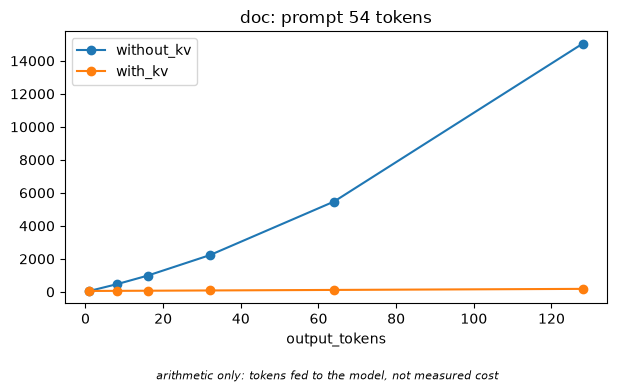

In [4]:
sweep = []
for output in (1, 8, 16, 32, 64, 128):
    counted = kv_math.tokens_processed_without_kv(54, output)
    sweep.append({"output_tokens": output, "without_kv": counted["without_kv"], "with_kv": counted["with_kv"]})
view.sweep_chart(sweep, "output_tokens", ["without_kv", "with_kv"],
                 note="arithmetic only: tokens fed to the model, not measured cost",
                 title="doc: prompt 54 tokens")

## 2. block과 `KVCacheBlock`

vLLM은 KV 메모리를 일정한 크기의 block으로 나누고 block 단위로 요청에 나눠 줍니다. 코드의 기본값은 16 token입니다(P2-04). 사용자가 지정하지 않으면 `CacheConfig`가 이 값을 채웁니다. 다만 16은 **폴백**이고 최종값이 아닙니다. model을 올린 뒤 `update_block_size_for_backend`([vllm/platforms/interface.py:750](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/platforms/interface.py#L750))가, `--block-size`를 주지 않았다면 attention backend가 받는 크기로 바꿉니다. hybrid model(층 종류가 섞인 model, 02b)은 사용자가 준 값까지 다시 맞춥니다. 실제 클래스를 CPU에서 불러 본 결과(실제 클래스 실행, `data/reference_specs.json`, `docs/reference/specs.md`) GLM-5.3-Flash는 BF16에 draft가 없을 때 TP1 4352, TP4 1152였고(TP4는 TP 그룹의 크기만 4로 바꾼 호출이고 다른 설정은 그대로입니다), draft 5개면 TP1 4480, FP8 계열이면 8576 또는 8704였습니다. 이 호출은 패치를 넣어, CPU 플랫폼이 block 크기를 정하는 재정의(`CpuPlatform`)를 건너뛰고 기본 구현을 부른 것입니다. 수업 구성인 TP4와 MTP(5) 조합의 값은 없습니다. DeepSeek-V4-Flash는 256, DeepSeek-V4.1-Flash는 backend와 GPU 세대(코드의 SM 값. SM90은 Hopper, SM100은 Blackwell입니다. `docs/reference/specs.md`의 표에는 SM120도 있고 02c에서 다시 봅니다)에 따라 64 또는 128이었습니다. 서버 시작 로그로 확인한 값은 아닙니다.

여기서 가장 중요한 사실은 **block이 두 세계에 나뉘어 있다**는 것입니다.

| | metadata | 값 |
|---|---|---|
| 무엇 | `KVCacheBlock` 객체 | KV cache tensor의 한 구간 |
| 어디 | EngineCore 프로세스의 Python 객체 | GPU worker의 GPU 메모리 |
| 담는 것 | ID, 참조 수, hash, 연결 리스트 포인터 | token별 K, V |
| 연결 | `block_id`가 같으면 같은 block | tensor의 첫 번째 축 번호가 `block_id` |

`KVCacheBlock`이 드는 칸은 다음과 같고 KV 값은 없습니다(P2-06, P2-07).

| 칸 | 뜻 |
|---|---|
| `block_id` | pool 안의 번호 |
| `ref_cnt` | 이 block을 쓰는 요청 수(`02b`) |
| `_block_hash` | 꽉 찼을 때 붙는 hash(`02b`) |
| `_block_hash_num_tokens` | 그 hash가 덮는 token 수 |
| `prev_free_block`, `next_free_block` | free queue의 연결 포인터(`02b`) |
| `pool` | 소속 pool |
| `is_null` | null block 표지 |

그래서 scheduler는 GPU 메모리를 건드리지 않고 block을 나눠 주고 돌려받을 수 있습니다.

**공식 문서.** 설계 문서의 `KVCacheBlock` 예시([docs/design/prefix_caching.md:107](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/prefix_caching.md#L107))가 단순화한 클래스를, 그 아래 설계 항목([docs/design/prefix_caching.md:123](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/prefix_caching.md#L123))이 pool을 미리 만든다는 설계를 설명합니다.

**코드.** 기본값 [vllm/config/cache.py:72](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L72), 필드 선언 [vllm/config/cache.py:74](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L74), 대입 [vllm/config/cache.py:345](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L345). 실제 클래스 [vllm/v1/core/kv_cache_utils.py:176](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L176)부터 [vllm/v1/core/kv_cache_utils.py:200](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L200)까지. pool 생성 [vllm/v1/core/block_pool.py:172](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L172), null block [vllm/v1/core/block_pool.py:187](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L187).

첫 free block을 꺼내 null block(ID 0)으로 쓰기 때문에 실제 할당 ID는 1부터입니다(P2-08). 아래에서 `kv_sim`이 무엇을 모델링하지 않았는지 먼저 보고, pool을 만들어 확인합니다.

In [5]:
for line in kv_sim.NOT_MODELED:
    print("-", line)

pool = kv_sim.BlockPool(12)
view.table([{
    "num_blocks": len(pool.blocks),
    "null block ID": pool.null_block.block_id,
    "is_null": pool.null_block.is_null,
    "free 개수": pool.num_free(),
    "free queue 앞 3개": pool.free_queue.ids()[:3],
}])

- watermark(대기 중이거나 preempt된 요청에 남겨 두는 여유 block)는 모델링하지 않았다. vllm/v1/core/kv_cache_manager.py:512-516
- scheduler_reserve_full_isl(기본 True)은 모델링하지 않았다. vLLM은 새 요청의 전체 입력이 들어갈 free block이 없으면 들여보내지 않지만 schedule은 첫 chunk에 필요한 block만 보고 들여보낸다. vllm/config/scheduler.py:190, vllm/v1/core/sched/scheduler.py:1270, vllm/v1/core/kv_cache_manager.py:522-539
- sliding window와 skipped block은 KVManagerSim에 없다. HybridPoolToy가 block 수 규칙만 장난감으로 보인다.
- KV connector(외부 KV 전송)와 외부 계산 token은 모델링하지 않았다.
- 마지막 partial block 등록(partial tail 등록)은 모델링하지 않았다. 꽉 차지 않은 block은 hash가 없다.
- max_model_len 상한(allocate_slots의 min(..., max_model_len))은 적용하지 않았다.
- hash_block_size와 group block_size의 분리는 모델링하지 않았다. 둘이 같은 한 group만 있다.
- 실제 KV 값은 없다. slot_contents는 어느 요청의 몇 번째 token이 쓰였는지 보여 주는 표지다.
- 실제 hash 값은 vLLM과 다르다(sha256 앞 12자). 같은 token이면 같은 hash라는 구조만 같다.
- LoRA, 멀티모달, prompt embeds의 extra key와 copy-on-write(partial hit)는 모델링하지 않았다.
- pool을 직접 두 번 free하면 ValueError를 낸다. vLLM은 이 검사를 하지 않는다(교육용 안전장치).


,num_blocks,null block ID,is_null,free 개수,free queue 앞 3개
0,12,0,True,11,"[1, 2, 3]"


**관찰할 것.** `free queue 앞 3개` 칸의 첫 값과 `null block ID` 칸을 비교하세요. 그리고 `num_blocks`와 `free 개수`의 차이가 어디서 왔는지 말해 보세요.

이번에는 block 하나가 몇 byte인지 봅니다. 일반 attention layer의 식은 `num_kv_heads * block_size * (head_size + head_size_v) * dtype 크기`입니다(P2-05). `head_size_v`를 따로 주지 않으면 `head_size`와 같아져서 K와 V를 합친 2배가 됩니다.

**코드.** `head_size_v` 기본값 대입 [vllm/v1/kv_cache_interface.py:536](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L536), state 하나의 byte [vllm/v1/kv_cache_interface.py:549](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L549), page 크기 [vllm/v1/kv_cache_interface.py:553](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L553). FlashAttention backend의 layer별 tensor shape은 `[num_blocks, num_kv_heads, block_size, 2 * head_size]`입니다([vllm/v1/attention/backends/flash_attn.py:1197](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/flash_attn.py#L1197), P2-18).

이 수업은 가상 모델 `toy-8L`(MHA, 8층, head 8, head 차원 64)로 계산합니다. **GLM-5.3-Flash가 아닙니다.** 아래 출력의 마지막 두 줄은 byte 식과 tensor 모양이 같은 말을 하는지 검산합니다. TP로 KV head가 나뉘는 것은 계산하지 않습니다.

In [6]:
HEADS, HEAD_DIM, LAYERS, NUM_BLOCKS = 8, 64, 8, 12
bf16 = kv_math.block_bytes(HEADS, HEAD_DIM, "bfloat16")
fp8 = kv_math.block_bytes(HEADS, HEAD_DIM, "fp8")
tensor_shape = [NUM_BLOCKS, HEADS, DEFAULT_BLOCK_SIZE, 2 * HEAD_DIM]
display(view.table([
    {"dtype": "bfloat16", "층당 block byte": bf16, "8층 block byte": bf16 * LAYERS},
    {"dtype": "fp8", "층당 block byte": fp8, "8층 block byte": fp8 * LAYERS},
]))
print("층당 tensor 모양:", tensor_shape)
print("모양의 곱 * 2 byte :", int(np.prod(tensor_shape)) * 2)
print("block 수 * 층당 byte:", NUM_BLOCKS * bf16)

,dtype,층당 block byte,8층 block byte
0,bfloat16,32768,262144
1,fp8,16384,131072


층당 tensor 모양: [12, 8, 16, 128]
모양의 곱 * 2 byte : 393216
block 수 * 층당 byte: 393216


pool을 그림으로 봅니다. 아직 아무도 쓰지 않았으므로 ID 0을 빼면 모두 비어 있습니다. 칸의 색은 범례를 따릅니다. `null`은 ID 0, `free`는 비었고 hash도 없음, `cached`는 비었지만 hash가 있음(`02b`), `used`는 요청 하나가 씀, `shared`는 여럿이 씀(`02b`)입니다.

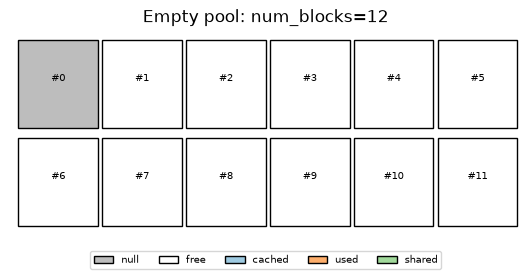

In [7]:
view.block_grid(kv_sim.KVManagerSim(12).snapshot(), ncols=6, title="Empty pool: num_blocks=12")

pool은 시작할 때 크기가 정해지고 그 뒤로 늘어나지 않습니다. 그러면 free block보다 많이 달라고 하면 어떻게 될까요. 실제 `get_new_blocks`([vllm/v1/core/block_pool.py:666](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L666))는 모자라면 [vllm/v1/core/block_pool.py:679](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L679)에서 `ValueError`를 냅니다. 수업 모델은 그 자식 클래스인 `KVPoolExhausted`를 냅니다.

In [8]:
# 실패 재현: free block보다 많은 block을 요청한다
exhausted = kv_sim.BlockPool(12)
try:
    exhausted.get_new_blocks(99)
except kv_sim.KVPoolExhausted as error:
    print(type(error).__name__, "/", error)
    print("requested =", error.requested, ", free =", error.free)
print("실패한 뒤 free 개수:", exhausted.num_free())

KVPoolExhausted / free block이 모자랍니다: 99개가 필요한데 free는 11개입니다 (부족 88개).
requested = 99 , free = 11
실패한 뒤 free 개수: 11


**관찰할 것.** 예외 메시지에 나온 요청 수와 남은 수, 그리고 실패한 뒤의 free 개수를 읽으세요. 일부만 나눠 주었습니까?

실제 서버의 정상 경로는 여기까지 오지 않습니다. `allocate_slots`가 필요한 block 수를 먼저 세어 모자라면 [vllm/v1/core/kv_cache_manager.py:577](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L577)에서 `None`을 돌려줍니다(P2-32). 그 `None`을 받은 scheduler가 무엇을 하는지는 `02b`의 preempt에서 봅니다.

수업 모델을 믿어도 되는 범위를 확인합니다. `data/reference_kv.json`에는 v0.32.0 소스의 실제 `KVCacheManager`를 CPU에서 돌린 결과가 들어 있습니다(`docs/REFERENCE_RUN.md`). 같은 입력을 `KVManagerSim`에도 넣어 block ID, 적중 token 수, 참조 수, free queue 순서를 행 단위로 비교했습니다. 범위는 단일 full-attention group, block 16, 6개 입력이고 hash 값 자체는 비교에서 뺐습니다. 이 범위에서만 실제 클래스와 같은 결과이고, **GPU 서버가 이렇게 동작한다는 뜻이 아닙니다.** 뒤의 `doc`, `faq`, `chat` 추적은 이 대조에 없는 입력이므로 수업 모델의 출력입니다. 아래 셀은 파일의 상태를 그대로 보여 줍니다. 실행되지 않았다면 그렇다고 출력합니다. 표의 `R1`, `R2`는 대조 파일의 이름이고 길이는 54, 20 token입니다.

In [9]:
reference_rows = kv_sim.reference_rows()
display(view.table(reference_rows, ["name", "match", "status"]))
scenario = next((s for s in REFERENCE.get("scenarios", []) if s["name"] == "sequential_allocate"), None)
if REFERENCE["status"] != "ran" or scenario is None or scenario.get("real") is None:
    print("실행하지 못했습니다. 사유:", REFERENCE.get("reason"))
else:
    display(view.table([
        {"요청": real["request_id"], "실제 block table": real["block_table"],
         "수업 모델 block table": sim["block_table"], "같은가": real == sim}
        for real, sim in zip(scenario["real"], scenario["sim"])
    ]))

,name,match,status
0,sequential_allocate,True,ran
1,prefix_hit_repeat,True,ran
2,hit_cap_num_tokens_minus_1,True,ran
3,different_salt,True,ran
4,free_then_reuse_order,True,ran
5,eviction_under_pressure,True,ran


,요청,실제 block table,수업 모델 block table,같은가
0,R1,"[1, 2, 3, 4]","[1, 2, 3, 4]",True
1,R2,"[5, 6]","[5, 6]",True


### 문서와 코드가 다를 때

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| 강의 PDF 3장은 "교육용 block size=4"라고 밝히고, 4장 Packed Token 슬라이드는 표시 없이 `block size = 4`로만 적는다 | 16은 폴백이다. 필드는 `default=None`이고 설정 시점에 16을 대입한 뒤(`vllm/config/cache.py:344-345`), 플랫폼이 attention backend의 선호 크기로 덮어쓴다(`vllm/platforms/interface.py:769-781`). hybrid model은 페이지 크기를 맞추려고 더 키울 수 있고(`vllm/platforms/interface.py:1094-1095`), CPU 플랫폼은 16, 128, 256으로 따로 정한다(`vllm/platforms/cpu.py:280-293`). 4는 설명용 값이다. 실제 model의 block 크기는 서버 시작 로그에서 확인해야 한다 | D-13 |

### PDF에서는

노트북은 PDF 없이 읽히도록 썼습니다. PDF를 함께 본다면 아래 장을 가리킵니다.

| PDF 장 | PDF 내용 | 이 노트북의 판단 | 근거 |
|---|---|---|---|
| 3장 KV 메모리 공식 | `2·B·L·T·nkv·dh·b`, MLA와 recurrent state는 별도 모델 | 일치. 적용 범위를 스스로 한정한 표현이 코드와 맞다. 절 6에서 계산한다. 단 TP를 늘려도 rank당 KV가 항상 비례해 줄지는 않는다. cache가 TP에 걸쳐 나뉘는 조각 수에는 상한 `max_tp_shards`가 있고, 그 너머의 rank는 복제본을 든다(`vllm/v1/kv_cache_interface.py:513-515`) | D-12 |
| 3장 논리·물리 블록 | 교육용 block size 4 | 표현 주의. 16은 폴백이고 backend와 model에 따라 달라진다. 위 표와 같다 | D-13 |
| 4장 Packed Token과 Slot Mapping | `block size = 4`로 계산한 slot 예 | 식과 숫자는 일치. 교육용 값이라는 표시만 없다. 절 4에서 재현한다 | D-13, D-14 |

**왜 이렇게 설계했나.** 설계 문서의 pool 항목([docs/design/prefix_caching.md:123](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/prefix_caching.md#L123))은 block을 pool로 미리 만들면 Python 객체 생성 비용을 피하고 모든 block을 항상 추적할 수 있다고 적습니다. PR #9972도 자기 구조의 장점으로 Python 객체를 새로 만들지 않는다는 점을 듭니다. metadata와 값을 분리한 이유를 직접 적은 문장은 소스와 공식 문서에서 찾지 못했습니다. 다만 위 표에서 보듯 둘은 사는 프로세스가 다르므로, block 배정은 ID를 주고받는 일로 끝납니다.

## 3. block table과 request의 연결

block은 pool에 있고, 어떤 요청이 어떤 block을 쓰는지는 어딘가에 적혀야 합니다. 그 기록이 **block table**입니다. 요청의 position 순서대로 block ID를 적은 목록입니다. `doc`이 앞에서부터 block 4, 5, 6, 7을 쓴다면 `[4, 5, 6, 7]`입니다.

이 목록은 네 곳에서 다른 모습으로 나타납니다.

| 위치 | 이름 | 프로세스 | 하는 일 |
|---|---|---|---|
| `Request` 객체 | 없음. `block_hashes`와 함수 `_block_hasher`만 든다 | EngineCore | 요청은 block 목록을 들지 않는다(P2-13) |
| group별 `SingleTypeKVCacheManager` | `req_to_blocks` | EngineCore | request ID를 키로 block 목록을 든다(P2-12) |
| `SchedulerOutput` | `block_ids` 또는 `new_block_ids` | EngineCore에서 worker로 | 이번 step에 알려 줄 ID를 나른다(P2-14) |
| worker | `BlockTables` 또는 `MultiGroupBlockTable` | GPU worker | 받은 ID를 기존 목록 뒤에 붙여 든다. preempt에서 돌아온 요청은 예외다(P2-14, P2-15) |

scheduler가 보내는 내용은 요청의 상태에 따라 다릅니다. 새 요청은 block ID 전체(`NewRequestData.block_ids`)를, 이미 도는 요청은 이번 step에 새로 붙은 ID(`CachedRequestData.new_block_ids`, 없으면 None)만 보냅니다. preempt에서 돌아온 요청은 다릅니다. MRV2는 새 요청 목록에 합쳐 전체를 다시 보내고, V1 경로는 `resumed_req_ids`로 표시해 worker의 기존 목록을 덮어쓰게 합니다(코드 읽기, [vllm/v1/core/sched/output.py:140](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/output.py#L140), [vllm/v1/core/sched/scheduler.py:1418](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1418), [vllm/v1/core/sched/scheduler.py:1730](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1730)).

Model Runner V2(MRV2)는 `BlockTables`, V1 runner는 `MultiGroupBlockTable`을 씁니다. 어느 쪽인지는 조건으로 갈립니다. 환경변수가 없으면 Triton이 있고 미지원 기능이 없을 때 V2이고, 아니면 V1입니다(P2-15).

**공식 문서.** 설계 문서의 Request blocks 항목([docs/design/prefix_caching.md:135](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/prefix_caching.md#L135))은 request ID에서 block ID로 가는 mapping이라고만 적습니다. `paged_attention.md`는 아래 표를 보세요.

**코드.** `Request` [vllm/v1/request.py:225](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/request.py#L225). dict [vllm/v1/core/single_type_kv_cache_manager.py:125](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/single_type_kv_cache_manager.py#L125), coordinator를 거쳐 접근하는 곳 [vllm/v1/core/kv_cache_manager.py:851](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L851). 보내는 쪽 [vllm/v1/core/sched/output.py:47](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/output.py#L47), [vllm/v1/core/sched/output.py:150](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/output.py#L150), 주석 [vllm/v1/core/sched/output.py:140](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/output.py#L140). 받는 쪽 [vllm/v1/worker/gpu/model_runner.py:1236](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1236), [vllm/v1/worker/gpu/block_table.py:110](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/block_table.py#L110). 클래스 [vllm/v1/worker/gpu/block_table.py:17](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/block_table.py#L17), [vllm/v1/worker/gpu_input_batch.py:183](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu_input_batch.py#L183), 조건 [vllm/config/vllm.py:703](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L703).

수업의 고정 예제 E1을 만듭니다. pool은 12 block, block 크기 16, 이번 step의 token 예산은 32, threshold(`long_prefill_token_threshold`, `03`에서 다룹니다)는 0입니다. `chat`은 프롬프트 33 token을 계산했고 출력 token 하나가 막 생겼습니다. (`01`의 `chat` 프롬프트는 34 token이었지만, 이 예제는 decode token 하나를 보이려고 프롬프트를 33 token으로 둡니다.) `doc`은 54 token 중 32 token까지 계산했습니다. `faq`는 아직 waiting입니다. token ID는 요청마다 겹치지 않게 임의로 정했습니다. 이 함수는 뒤의 셀과 해보기에서 다시 씁니다. running을 먼저 돌고 남은 예산을 waiting에 주는 것은 `run_e1` 안에 직접 쓴 수업용 규칙입니다.

In [10]:
BASE = {"doc": 1000, "faq": 2000, "chat": 3000}


def ids(name, count, start=0):
    return list(range(BASE[name] + start, BASE[name] + start + count))


def run_e1(block_size=16, budget=32, num_blocks=12):
    manager = kv_sim.KVManagerSim(num_blocks, block_size=block_size)
    chat = manager.add_request("chat", ids("chat", 33))
    manager.schedule(chat)
    manager.append_output(chat, ids("chat", 1, start=33))
    doc = manager.add_request("doc", ids("doc", 54))
    manager.schedule(doc, 32)
    faq = manager.add_request("faq", ids("faq", 20))
    requests = (chat, doc, faq)
    worker = {r.request_id: manager.block_table(r) for r in (chat, doc)}
    before = [{"요청": r.request_id, "전체 token": r.num_tokens, "계산한 token": r.num_computed_tokens,
               "block table": manager.block_table(r), "위치": "running" if r.num_computed_tokens else "waiting"}
              for r in requests]
    first_event = len(manager.events)
    left, entries, step = budget, [], []
    for r in requests:
        count = min(r.num_tokens - r.num_computed_tokens, left)
        if count == 0:
            step.append({"요청": r.request_id, "이번 step token": 0, "보내는 칸": "-", "보내는 값": [],
                         "worker block table": worker.get(r.request_id, [])})
            continue
        start, is_new = r.num_computed_tokens, r.num_computed_tokens == 0
        result = manager.schedule(r, count)
        left -= count
        worker[r.request_id] = worker.get(r.request_id, []) + result.new_block_ids
        entries.append({"request_id": r.request_id, "token_ids": r.token_ids[start:start + count],
                        "num_computed_tokens": start, "block_table": result.block_table})
        step.append({"요청": r.request_id, "이번 step token": count,
                     "보내는 칸": "block_ids" if is_new else "new_block_ids", "보내는 값": result.new_block_ids,
                     "worker block table": worker[r.request_id]})
    return {"manager": manager, "requests": requests, "before": before, "step": step,
            "entries": entries, "first_event": first_event, "block_size": block_size}


E1 = run_e1()
display(view.table(E1["before"]))
view.table(E1["step"])

,요청,전체 token,계산한 token,block table,위치
0,chat,34,33,"[1, 2, 3]",running
1,doc,54,32,"[4, 5]",running
2,faq,20,0,[],waiting


,요청,이번 step token,보내는 칸,보내는 값,worker block table
0,chat,1,new_block_ids,[],"[1, 2, 3]"
1,doc,22,new_block_ids,"[6, 7]","[4, 5, 6, 7]"
2,faq,9,block_ids,[8],[8]


**관찰할 것.** 두 번째 표의 `보내는 칸`과 `보내는 값`을 요청별로 읽으세요. `chat`은 왜 비어 있습니까? `doc`의 `보내는 값`과 `worker block table`은 어떤 관계입니까? 예산을 합하면 얼마입니까?

한 step에 `chat`은 decode token, `doc`과 `faq`는 prefill 조각입니다. 단계 구분이 없다는 절 0의 주석이 이 표에서 그대로 보입니다. 같은 step에서 어떤 block이 어떻게 잡혔는지 그림과 추적으로 봅니다. 그림의 `new`는 이번 step에 새로 나간 block입니다.

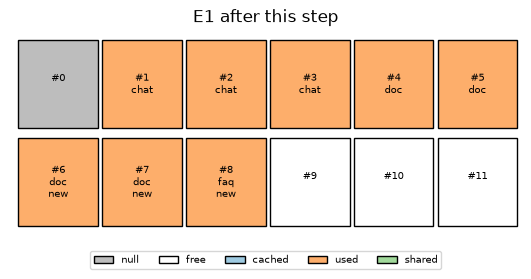

In [11]:
new_ids = [block for row in E1["step"] for block in row["보내는 값"]]
view.block_grid(E1["manager"].snapshot(), ncols=6, title="E1 after this step",
                mark={block: "new" for block in new_ids})

In [12]:
view.trace_table(E1["manager"].events[E1["first_event"]:])

,step,actor,kind,request_id,detail
0,3,BlockPool,alloc,chat,"{""block_ids"": []}"
1,4,BlockPool,alloc,doc,"{""block_ids"": [6, 7]}"
2,4,BlockPool,hash_register,doc,"{""block_id"": 6, ""block_hash"": ""5d224dbf811f"", ""num_tokens"": 48}"
3,5,KVManagerSim,hit,faq,"{""hit_tokens"": 0, ""block_ids"": [], ""max_hit_tokens"": 19}"
4,5,BlockPool,alloc,faq,"{""block_ids"": [8]}"


표의 `step` 칸은 수업 모델의 호출 순번입니다. 준비 호출 두 번 뒤의 호출 3, 4, 5가 모두 E1의 한 step입니다.

**관찰할 것.** 추적의 `kind` 칸을 읽으세요. `alloc`은 block을 나눠 준 일, `hash_register`는 block이 꽉 차서 hash가 붙은 일, `hit`은 prefix cache를 조회한 일입니다. 뒤의 둘은 `02b`의 주제이므로 지금은 `detail`에서 block ID만 봅니다. 이번 step에 새로 나간 block 중 `hash_register`가 없는 것은 어느 것이고, 왜 그렇습니까?

### 문서와 코드가 다를 때

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| `docs/design/paged_attention.md`는 block table과 paged KV를 설명하고 `csrc/attention/attention_kernels.cu`를 가리킨다([docs/design/paged_attention.md:8](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/paged_attention.md#L8)) | 같은 문서 맨 위 경고가 원본 논문에 기반한 역사 문서이고 지금 코드를 설명하지 않는다고 밝힌다([docs/design/paged_attention.md:3](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/paged_attention.md#L3)). 가리키는 파일은 v0.32.0에 없다. `csrc/attention/`에는 `dcp_utils`, `merge_attn_states.cu`, `mla`만 있다. 코드가 맞다. 개념 비유로만 읽고 구현 근거로 쓰지 않는다 | P2-70 |

**왜 이렇게 설계했나.** PR #25266(MRV2 도입) 본문은 persistent batch 제거, 대부분의 CPU 상태를 numpy 배열로 옮김, GPU에 상주하는 block table을 적습니다. 코드의 `BlockTables`가 이것과 대응합니다.

## 4. slot 공식

block table과 position이 있으면 slot이 하나로 정해집니다.

```text
slot = block_table[position // block_size] * block_size + position % block_size
```

손으로 계산하는 순서는 세 단계입니다. (1) position을 block 크기로 나눕니다. 몫은 요청의 몇 번째 block인가이고 나머지는 그 block 안의 offset입니다. (2) 몫을 index로 block table에서 block ID를 찾습니다. (3) `block ID * block_size + offset`을 계산합니다. 몫은 요청 안의 순번이고 block ID는 pool 전체의 번호입니다. 둘을 섞지 마세요.

**계산 주체는 scheduler가 아니라 worker입니다**(P2-16). scheduler가 보내는 것은 절 3에서 본 block ID 목록이고, 그 안에 slot은 없습니다. `slot_mapping`은 KV cache group마다 하나씩 만들어집니다(P2-17). 지금은 group이 하나인 경우만 봅니다.

**공식 문서.** 공식 문서에는 이 설명이 없습니다. 역사 문서인 `paged_attention.md`의 비유는 위 표의 범위로만 읽습니다.

**코드.** 식 [vllm/v1/worker/gpu/block_table.py:348](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/block_table.py#L348), MRV2의 Triton kernel [vllm/v1/worker/gpu/block_table.py:273](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/block_table.py#L273), V1 runner [vllm/v1/worker/block_table.py:153](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/block_table.py#L153), worker가 부르는 곳 [vllm/v1/worker/gpu/model_runner.py:1568](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1568), group 수가 모양에 들어가는 주석 [vllm/v1/worker/gpu/model_runner.py:1566](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1566).

**먼저 예측하세요.** `doc`의 block table은 `[4, 5, 6, 7]`입니다. position 37의 slot은 몇입니까? 세 단계를 종이에 적은 뒤 실행하세요.

In [13]:
def slot_rows(run, picks):
    size = run["block_size"]
    rows = []
    for name, positions in picks.items():
        request = run["manager"].requests[name]
        table = run["manager"].block_table(request)
        for position in positions:
            block_index, offset = divmod(position, size)
            rows.append({"요청": name, "position": position, "몫": block_index, "offset": offset,
                         "block ID": table[block_index], "block table": table,
                         "slot": kv_sim.slot_id(table, position, size)})
    return view.table(rows)


PICKS = {"chat": [33], "doc": [32, 37, 48, 53], "faq": [0, 8]}
slot_rows(E1, PICKS)

,요청,position,몫,offset,block ID,block table,slot
0,chat,33,2,1,3,"[1, 2, 3]",49
1,doc,32,2,0,6,"[4, 5, 6, 7]",96
2,doc,37,2,5,6,"[4, 5, 6, 7]",101
3,doc,48,3,0,7,"[4, 5, 6, 7]",112
4,doc,53,3,5,7,"[4, 5, 6, 7]",117
5,faq,0,0,0,8,[8],128
6,faq,8,0,8,8,[8],136


**관찰할 것.** 예측한 값을 `doc` 37 행의 `slot`과 비교하세요. 틀렸다면 `몫`, `block ID`, `offset` 칸 중 어디서 어긋났는지 찾습니다. `doc` 32와 `doc` 48 행의 `offset`도 보세요.

`doc`의 표는 우연히 번호가 이어져 있습니다. 그러면 slot 식이 왜 block table을 거쳐야 하는지 드러나지 않습니다. 번호가 끊기는 경우를 만들어 봅니다. `chat`이 끝나서 block을 반납한 뒤 `faq`가 나머지 11 token을 계산하면 `faq`는 어떤 block을 받을까요. 반납 순서의 규칙은 `02b`에서 배우므로 지금은 결과만 봅니다.

chat 반납 뒤 faq의 새 block: [3]
faq block table: [8, 3]
free queue: [9, 10, 11, 2, 1]


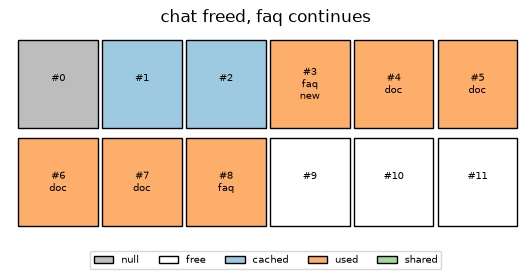

In [14]:
after = run_e1()
chat, doc, faq = after["requests"]
after["manager"].free(chat)
result = after["manager"].schedule(faq)
print("chat 반납 뒤 faq의 새 block:", result.new_block_ids)
print("faq block table:", result.block_table)
print("free queue:", after["manager"].free_queue_ids())
view.block_grid(after["manager"].snapshot(), ncols=6, title="chat freed, faq continues", mark={result.new_block_ids[0]: "new"})

block table이 끊겼습니다. 이제 "요청의 block은 이어져 있다"고 가정한 식을 맞는 식과 나란히 놓습니다. 틀린 식은 `block_table[0] * block_size + position`입니다. 세 번째 행의 표는 대조 파일의 `eviction_under_pressure` 시나리오에서 실제 클래스가 낸 block table입니다(상태가 `ran`일 때만 넣습니다).

In [15]:
# 실패 재현: 연속 배치라고 가정한 잘못된 식
def wrong_slot(table, position, size=16):
    return table[0] * size + position


tables = {"doc": ([4, 5, 6, 7], 54), "faq": (result.block_table, 20)}
if REFERENCE["status"] == "ran":
    pressure = next(s for s in REFERENCE["scenarios"] if s["name"] == "eviction_under_pressure")
    tables["R2 (real class)"] = (pressure["real"][2]["block_table"], 64)
else:
    print("실제 클래스 결과 없음:", REFERENCE.get("reason"))

summary = []
for name, (table, length) in tables.items():
    wrong_positions = [p for p in range(length) if wrong_slot(table, p) != kv_sim.slot_id(table, p)]
    summary.append({"표": name, "block table": table, "token 수": length,
                    "처음 달라지는 position": wrong_positions[0] if wrong_positions else "없음",
                    "틀린 칸 수": len(wrong_positions)})
display(view.table(summary))

faq_table = result.block_table
view.table([{"faq position": p, "틀린 식": wrong_slot(faq_table, p), "맞는 식": kv_sim.slot_id(faq_table, p)}
            for p in range(13, 20)])

,표,block table,token 수,처음 달라지는 position,틀린 칸 수
0,doc,"[4, 5, 6, 7]",54,없음,0
1,faq,"[8, 3]",20,16,4
2,R2 (real class),"[4, 5, 3, 2]",64,32,32


,faq position,틀린 식,맞는 식
0,13,141,141
1,14,142,142
2,15,143,143
3,16,144,48
4,17,145,49
5,18,146,50
6,19,147,51


**관찰할 것.** 첫 표의 `처음 달라지는 position`을 세 행 비교하고, 그 값이 block 크기와 어떤 관계인지 말해 보세요. `doc` 행은 왜 "없음"입니까? 둘째 표에서 틀린 식이 가리키는 칸은 pool의 어느 block에 속합니까? 그 block의 주인은 누구입니까? 위 그림에서 찾아보세요.

이 실패에는 예외가 없습니다. 틀린 식도 그럴듯한 번호를 돌려주고, 번호가 이어진 표로만 시험하면 통과합니다.

이번에는 PDF의 예를 같은 함수로 재현합니다. PDF는 block 크기 4에서 첫 요청의 slot을 20, 21, 22, 23, 4, 5로, 둘째 요청의 slot을 8, 9로 적습니다. 이 숫자가 block `[5, 1]`과 `[2]`에서 나온다는 것을 확인했습니다(D-14). 같은 block table을 실제 기본값 16으로도 계산합니다.

In [16]:
pdf_cases = [("PDF 첫 요청", [5, 1], 6, [20, 21, 22, 23, 4, 5]), ("PDF 둘째 요청", [2], 2, [8, 9])]
rows = []
for name, table, length, printed in pdf_cases:
    size_4 = kv_sim.slot_mapping(table, 0, length, block_size=4)
    size_16 = kv_sim.slot_mapping(table, 0, length, block_size=16)
    rows.append({"요청": name, "block table": table, "PDF의 값": printed, "block 4로 계산": size_4,
                 "같은가": size_4 == printed, "block 16으로 계산": size_16})
view.table(rows)

,요청,block table,PDF의 값,block 4로 계산,같은가,block 16으로 계산
0,PDF 첫 요청,"[5, 1]","[20, 21, 22, 23, 4, 5]","[20, 21, 22, 23, 4, 5]",True,"[80, 81, 82, 83, 84, 85]"
1,PDF 둘째 요청,[2],"[8, 9]","[8, 9]",True,"[32, 33]"


**관찰할 것.** `같은가` 칸으로 PDF의 산수를 확인하고, 같은 block table인데 `block 16으로 계산` 칸이 어떻게 달라지는지 읽으세요. 첫 요청의 6 token이 block 크기 16에서는 block을 몇 개 쓰게 될까요? 그래서 PDF의 slot 숫자를 실제 서버의 숫자로 옮겨 말하면 안 됩니다. 16도 폴백일 뿐이고 실제 block 크기는 backend와 model에 따라 달라집니다(D-13).

**왜 이렇게 설계했나.** 식이 왜 이 모양인지 적은 문장은 소스와 공식 문서에서 찾지 못했습니다. 아래는 **수업의 해석**입니다. 위 실험에서 `chat`이 돌려준 block을 `faq`가 이어 받자 번호가 끊겼습니다. block을 재사용하는 한 요청의 block을 이어 놓을 수 없고, 그래서 block table이라는 한 단계의 간접 참조가 필요합니다.

## 5. packed batch

forward 한 번에 여러 요청이 들어갑니다. 요청마다 길이가 다르므로, 계산할 token을 한 줄로 이어 붙이고 "어디부터 어디까지가 누구인가"를 배열로 따로 적습니다. 이것이 packed batch입니다(P2-19). 배열은 다음과 같습니다.

| 배열 | 길이 | 값을 정하는 규칙 |
|---|---|---|
| `input_ids` | 이번 step token 수 | 이 step에서 새로 계산하는 token. 이미 KV가 있는 token은 뺀다 |
| `query_start_loc` | 요청 수 + 1 | 요청별 이번 step token 수의 누적합. 앞에 0 |
| `positions` | 이번 step token 수 | 각 요청의 `num_computed_tokens`에서 시작해 하나씩 커진다 |
| `seq_lens` | 요청 수 | `num_computed_tokens + 이번 step token 수` |
| `slot_mapping` | 이번 step token 수. padding이 있으면 그만큼 늘고 그 칸의 값은 -1이다(절 6) | 절 4의 식 |

두 길이를 구분하세요. `query_start_loc`의 간격은 **이번 step**의 token 수이고, `seq_lens`는 **이 step이 끝난 뒤** 요청의 문맥 길이입니다.

`input_ids`를 채우는 방법은 구간마다 다릅니다(P2-20). MRV2에서 prefill 구간은 `prepare_prefill_inputs`가 프롬프트에서 가져오고, decode 구간은 `combine_sampled_and_draft_tokens`가 직전 step에 sampling한 token과 draft token으로 채웁니다. 그래서 `chat` 한 token과 `doc` 22 token은 출처가 다릅니다.

**공식 문서.** 공식 문서에는 이 설명이 없습니다.

**코드.** 누적합 [vllm/v1/worker/gpu/model_runner.py:1430](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1430). prefill 분기 [vllm/v1/worker/gpu/model_runner.py:1449](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1449), 함수 [vllm/v1/worker/gpu/input_batch.py:320](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/input_batch.py#L320). position과 길이 [vllm/v1/worker/gpu/model_runner.py:1461](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1461), [vllm/v1/worker/gpu/input_batch.py:374](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/input_batch.py#L374), [vllm/v1/worker/gpu/input_batch.py:380](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/input_batch.py#L380). sampling한 token을 읽는 곳의 주석 [vllm/v1/worker/gpu/model_runner.py:1470](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1470).

**수업 모델의 순서입니다.** 아래 배열은 이 시뮬레이터가 넣은 순서(chat, doc, faq)입니다. MRV2는 `sort_batch_req_ids`([vllm/v1/worker/gpu/model_runner.py:2435-2447](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L2435-L2447))로 draft가 있는 요청, token 수가 decode 길이와 같은 요청, 그다음 token 수가 적은 요청 순으로 정렬합니다(P2-74, 코드 읽기, 호출은 [vllm/v1/worker/gpu/model_runner.py:1291](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1291)). 그래서 실제 배열의 순서는 다를 수 있습니다. 읽는 법은 같습니다.

**먼저 예측하세요.** E1에서 이번 step의 token 수는 `chat` 1, `doc` 22, `faq` 9입니다. `query_start_loc`의 값 네 개를 적으세요. `seq_lens`의 값 세 개도 적으세요.

In [17]:
def array_rows(packed):
    rows = []
    starts = packed["query_start_loc"]
    for i, name in enumerate(packed["request_ids"]):
        lo, hi = starts[i], starts[i + 1]
        rows.append({"요청": name, "시작": lo, "끝": hi, "이번 step token": hi - lo,
                     "position": f"{packed['positions'][lo]}~{packed['positions'][hi - 1]}",
                     "input_ids": f"{packed['input_ids'][lo]}~{packed['input_ids'][hi - 1]}",
                     "seq_lens": packed["seq_lens"][i]})
    return view.table(rows)


batch = kv_sim.packed_batch(E1["entries"])
for name in ("request_ids", "query_start_loc", "seq_lens", "num_tokens", "positions", "input_ids", "slot_mapping"):
    print(f"{name:16}", batch[name])
array_rows(batch)

request_ids      ['chat', 'doc', 'faq']
query_start_loc  [0, 1, 23, 32]
seq_lens         [34, 54, 9]
num_tokens       32
positions        [33, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 0, 1, 2, 3, 4, 5, 6, 7, 8]
input_ids        [3033, 1032, 1033, 1034, 1035, 1036, 1037, 1038, 1039, 1040, 1041, 1042, 1043, 1044, 1045, 1046, 1047, 1048, 1049, 1050, 1051, 1052, 1053, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008]
slot_mapping     [49, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 128, 129, 130, 131, 132, 133, 134, 135, 136]


,요청,시작,끝,이번 step token,position,input_ids,seq_lens
0,chat,0,1,1,33~33,3033~3033,34
1,doc,1,23,22,32~53,1032~1053,54
2,faq,23,32,9,0~8,2000~2008,9


**관찰할 것.** `query_start_loc`의 이웃한 값 차이가 무엇과 같은지, `seq_lens`의 `doc` 값이 `positions`의 `doc` 구간 마지막 값과 어떤 관계인지 읽으세요. `input_ids`에 `doc`의 앞 32 token(ID 1000~1031)이 있습니까? 위 표의 `시작`, `끝` 칸은 배열 안의 index입니다.

이번에는 `slot_mapping`을 block table과 대조합니다. 한 줄로 붙인 slot을 block 단위로 묶으면, 절 4의 식이 block마다 어떻게 나타나는지 보입니다. `검산` 칸은 slot의 시작 값이 `block ID * 16 + 시작 position의 offset`과 같은지 확인합니다.

In [18]:
def segments(packed, entries, size=16):
    rows = []
    starts = packed["query_start_loc"]
    for i, entry in enumerate(entries):
        lo, hi = starts[i], starts[i + 1]
        grouped = {}
        for position, slot in zip(packed["positions"][lo:hi], packed["slot_mapping"][lo:hi]):
            grouped.setdefault(position // size, []).append((position, slot))
        for block_index, pairs in grouped.items():
            block = entry["block_table"][block_index]
            rows.append({"요청": entry["request_id"], "block table": entry["block_table"], "몫": block_index, "block ID": block,
                         "position": f"{pairs[0][0]}~{pairs[-1][0]}", "slot": f"{pairs[0][1]}~{pairs[-1][1]}",
                         "검산": pairs[0][1] == block * size + pairs[0][0] % size})
    return view.table(rows)


segments(batch, E1["entries"])

,요청,block table,몫,block ID,position,slot,검산
0,chat,"[1, 2, 3]",2,3,33~33,49~49,True
1,doc,"[4, 5, 6, 7]",2,6,32~47,96~111,True
2,doc,"[4, 5, 6, 7]",3,7,48~53,112~117,True
3,faq,[8],0,8,0~8,128~136,True


**관찰할 것.** 표에서 `doc`이 몇 행으로 나뉘는지, 각 행의 `block ID`가 절 3 그림의 어느 칸인지 찾으세요. `doc`의 block 4와 5는 왜 이 표에 없습니까? `chat`의 block 3에서 이번 step에 쓰이는 칸은 몇 개입니까?

**왜 이렇게 설계했나.** 이미 계산한 token을 다시 넣지 않는 것이 KV의 목적이고, `input_ids`가 계산할 token만 담는 것은 그 직접적인 결과입니다(수업의 해석).

## 6. 쓰기와 읽기, CUDA graph padding

forward 안에서 KV cache는 두 번 쓰입니다. 쓰는 쪽과 읽는 쪽은 **서로 다른 번호**를 봅니다.

| | 쓰기 | 읽기 |
|---|---|---|
| 대상 | 이번 step에 계산한 token의 새 K, V | 이미 저장된 K, V |
| 보는 것 | `slot_mapping` | block table과 `seq_lens` |
| 단위 | token 한 칸마다 번호 하나 | 요청마다 block 목록과 길이 |
| 코드 | [vllm/v1/attention/backends/flash_attn.py:1452](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/flash_attn.py#L1452) | [vllm/v1/attention/backends/flash_attn.py:1482](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/flash_attn.py#L1482), [vllm/v1/attention/backends/flash_attn.py:960](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/flash_attn.py#L960) |

쓰기는 token별 번호를 따라 칸에 넣습니다. 읽기는 kernel이 요청의 block 목록과 길이를 받아 찾아갑니다(P2-01). kernel 내부의 읽기 순서는 이 노트북이 따라가지 않았으므로 여기서 말하지 않습니다.

**padding.** CUDA graph는 capture한 크기대로 재생합니다. 그래서 실제 token 수가 capture 크기보다 적으면 `num_tokens_after_padding = max(num_tokens, batch_desc.num_tokens)`로 올립니다(P2-21). 이때 늘어난 padding token에도 slot 칸이 생기는데, 값은 `PAD_SLOT_ID`, 곧 -1입니다. 쓰기 kernel은 slot이 음수이면 건너뜁니다. 그래서 padding token은 KV 칸을 차지하지 않습니다.

full 모드는 요청 수도 올립니다. 늘어난 자리의 `query_start_loc`을 전체 token 수로 채워 값이 줄지 않게 합니다(P2-22).

padding이 graph에만 있는 것도 아닙니다. 코드 주석은 batch descriptor가 graph padding이나 DP padding을 가질 수 있다고 적습니다(P2-23).

**공식 문서.** 공식 문서에는 이 설명이 없습니다.

**코드.** 올리는 곳 [vllm/v1/worker/gpu/model_runner.py:1362](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1362). 상수 [vllm/v1/attention/backends/utils.py:51](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/utils.py#L51), 채우는 곳 [vllm/v1/worker/gpu/block_table.py:297](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/block_table.py#L297), 건너뛰는 곳 [csrc/cache_kernels.cu:339](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/csrc/cache_kernels.cu#L339). full 모드 [vllm/v1/worker/gpu/model_runner.py:1431](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1431), [vllm/v1/worker/gpu/model_runner.py:1433](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1433). DP padding [vllm/v1/worker/gpu/spec_decode/speculator.py:339](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/spec_decode/speculator.py#L339).

아래는 E1의 32 token을 capture 크기 40에 맞춘 경우입니다. 40은 수업이 정한 값입니다. `kv_sim.packed_batch`는 `slot_mapping`에만 -1을 채웁니다.

In [19]:
PAD_TO = 40
padded = kv_sim.packed_batch(E1["entries"], pad_to=PAD_TO)
print("num_tokens =", padded["num_tokens"], ", num_tokens_after_padding =", padded["num_tokens_after_padding"])
owner = []
for i, name in enumerate(padded["request_ids"]):
    owner += [name] * (padded["query_start_loc"][i + 1] - padded["query_start_loc"][i])
owner += ["(padding)"] * (padded["num_tokens_after_padding"] - padded["num_tokens"])
display(view.table([{"배열 index": i, "주인": owner[i], "slot": padded["slot_mapping"][i]} for i in range(28, PAD_TO)]))
written = [slot for slot in padded["slot_mapping"] if slot != kv_sim.PAD_SLOT_ID]
print("쓰이는 칸 수:", len(written), "/ 서로 다른 칸 수:", len(set(written)))

num_tokens = 32 , num_tokens_after_padding = 40


,배열 index,주인,slot
0,28,faq,133
1,29,faq,134
2,30,faq,135
3,31,faq,136
4,32,(padding),-1
5,33,(padding),-1
6,34,(padding),-1
7,35,(padding),-1
8,36,(padding),-1
9,37,(padding),-1


쓰이는 칸 수: 32 / 서로 다른 칸 수: 32


**관찰할 것.** `slot`이 -1인 칸의 `배열 index` 범위와 `주인`을 읽으세요. -1이 몇 개이고, `쓰이는 칸 수`와 어떤 관계입니까?

full 모드의 `query_start_loc`은 코드의 세 줄을 그대로 옮겨 계산합니다. 실제 요청은 3개이고, capture한 요청 수 5와 버퍼 크기 8은 수업이 정한 값입니다.

In [20]:
num_scheduled = np.array([1, 22, 9])
num_reqs, num_tokens, captured_reqs, max_num_reqs = 3, 32, 5, 8

query_start_loc = np.empty(max_num_reqs + 1, dtype=np.int32)
query_start_loc[0] = 0
np.cumsum(num_scheduled, out=query_start_loc[1:num_reqs + 1])
query_start_loc[num_reqs + 1:] = num_tokens

print("full 모드 query_start_loc:", query_start_loc[:captured_reqs + 1].tolist())
print("이웃한 값의 차이        :", np.diff(query_start_loc[:captured_reqs + 1]).tolist())

full 모드 query_start_loc: [0, 1, 23, 32, 32, 32]
이웃한 값의 차이        : [1, 22, 9, 0, 0]


**관찰할 것.** `이웃한 값의 차이` 줄에서 뒤의 두 값을 읽으세요. 값이 줄어드는 곳이 있습니까?

### 메모리 표: block byte가 용량을 정한다

마지막으로 절 2의 block byte가 전체 용량과 어떻게 이어지는지 수업의 고정 예제로 봅니다. 체크포인트를 읽지 않고, 가상 GPU 24 GiB와 가상 모델 `toy-8L`로 계산합니다. `2*B*L*T*n*d*b`(D-12)에서 B는 batch(요청 수), L은 층 수, T는 요청당 token 수, n은 head 수(MHA는 head 수, GQA는 KV head 수, MQA는 1), d는 head 차원, b는 dtype 한 원소의 byte입니다. 이 식은 일반 attention 층만 있는 모델에 맞는 식입니다. **GLM-5.3-Flash에는 이 식을 그대로 쓸 수 없습니다.** 층 종류마다 저장 방식이 다르고 층 구성 숫자가 v0.32.0 소스에 없습니다. TP를 늘릴 때도 rank당 KV가 항상 비례해 줄지는 않습니다. cache를 나누는 조각 수에 상한 `max_tp_shards`가 있고 그 너머의 rank는 복제본을 듭니다(D-12, 코드 읽기, [vllm/v1/kv_cache_interface.py:513](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L513)). 실제 vLLM은 기본 설정에서 KV 크기를 profiling으로 정합니다(P1-22). 아래 값은 산수이고 측정이 아닙니다.

In [21]:
raw = kv_math.raw_kv_bytes(batch=4, layers=8, tokens=1024, head_type="MHA", num_heads=8, head_dim=64)
print("2*B*L*T*n*d*b, B=4, L=8, T=1024, n=8, d=64, b=2:", raw, "byte =", raw / 2**20, "MiB")

rows = []
for dtype in ("bfloat16", "fp8"):
    per_block = kv_math.block_bytes(8, 64, dtype) * 8
    estimate = kv_math.capacity_from_budget(gpu_total_bytes=24 * 2**30, weights_bytes=12 * 2**30, other_bytes=2 * 2**30,
                                            block_bytes_all_layers=per_block, gpu_memory_utilization=0.92, max_model_len=8192)
    rows.append({"dtype": dtype, "8층 block byte": per_block, "KV byte": estimate.kv_bytes, "block 수": estimate.num_blocks,
                 "token 용량": estimate.capacity_tokens, "로그 형식": estimate.log_line})
view.table(rows)

2*B*L*T*n*d*b, B=4, L=8, T=1024, n=8, d=64, b=2: 67108864 byte = 64.0 MiB


,dtype,8층 block byte,KV byte,block 수,token 용량,로그 형식
0,bfloat16,262144,8675833937,33095,529520,"GPU KV cache size: 529,520 tokens, Maximum concurrency for 8,192 tokens per request: 64.64x"
1,fp8,131072,8675833937,66191,1059056,"GPU KV cache size: 1,059,056 tokens, Maximum concurrency for 8,192 tokens per request: 129.28x"


위 표는 block 하나의 byte가 달라지면 같은 KV byte에 들어가는 block 수가 달라진다는 산수만 보여 줍니다. 어떤 dtype을 실제로 쓸 수 있는지는 `04`에서 봅니다.

**왜 이렇게 설계했나.** 코드 주석이 이유를 둘 적습니다. `prepare_inputs`의 주석([vllm/v1/worker/gpu/model_runner.py:1432](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1432))은 FA3 같은 backend가 `query_start_loc`이 줄어들지 않기를 요구한다고 적습니다. `_compute_slot_mappings_kernel`의 주석([vllm/v1/worker/gpu/block_table.py:299](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/block_table.py#L299), 앞뒤 줄 포함)은 -1을 실제 token 수부터 채우는 이유를, chunked prefill 중 이전 chunk의 유효한 slot 번호가 틈에 남아 있을 수 있기 때문이라고 적습니다.

## 직접 해보기

값 하나만 바꾸고 다시 실행합니다. 바꾸기 전에 결과를 먼저 적으세요. 기본값은 위 본문과 같은 결과를 냅니다.

### 해보기 1

`BLOCK_SIZE`를 16에서 32로 바꿉니다.

**먼저 예측하세요.** `doc`의 block table은 어떻게 됩니까? `doc` position 37의 몫과 offset은 얼마입니까? 그 뒤 slot을 계산해 적으세요.

In [22]:
BLOCK_SIZE = 16  # 32로 바꿔 보세요
exercise_1 = run_e1(block_size=BLOCK_SIZE)
slot_rows(exercise_1, PICKS)

,요청,position,몫,offset,block ID,block table,slot
0,chat,33,2,1,3,"[1, 2, 3]",49
1,doc,32,2,0,6,"[4, 5, 6, 7]",96
2,doc,37,2,5,6,"[4, 5, 6, 7]",101
3,doc,48,3,0,7,"[4, 5, 6, 7]",112
4,doc,53,3,5,7,"[4, 5, 6, 7]",117
5,faq,0,0,0,8,[8],128
6,faq,8,0,8,8,[8],136


### 해보기 2

E1의 예산 `BUDGET`을 32에서 24로 바꿉니다. running을 먼저 도는 `run_e1`의 규칙은 그대로입니다.

**먼저 예측하세요.** 어느 요청이 token을 잃습니까? `query_start_loc`의 네 값과 `seq_lens`의 세 값을 적으세요. `faq`는 block을 몇 개 받습니까?

In [23]:
BUDGET = 32  # 24로 바꿔 보세요
exercise_2 = run_e1(budget=BUDGET)
packed_2 = kv_sim.packed_batch(exercise_2["entries"])
print("query_start_loc", packed_2["query_start_loc"])
print("seq_lens       ", packed_2["seq_lens"])
display(array_rows(packed_2))
view.table(exercise_2["step"])

query_start_loc [0, 1, 23, 32]
seq_lens        [34, 54, 9]


,요청,시작,끝,이번 step token,position,input_ids,seq_lens
0,chat,0,1,1,33~33,3033~3033,34
1,doc,1,23,22,32~53,1032~1053,54
2,faq,23,32,9,0~8,2000~2008,9


,요청,이번 step token,보내는 칸,보내는 값,worker block table
0,chat,1,new_block_ids,[],"[1, 2, 3]"
1,doc,22,new_block_ids,"[6, 7]","[4, 5, 6, 7]"
2,faq,9,block_ids,[8],[8]


### 해보기 3

`PAD_TO_TRY`를 40에서 64로 바꿉니다.

**먼저 예측하세요.** -1은 몇 개가 됩니까? `쓰이는 칸 수`는 달라집니까? pool에서 받는 block 수는 달라집니까?

In [24]:
PAD_TO_TRY = 40  # 64로 바꿔 보세요
packed_3 = kv_sim.packed_batch(E1["entries"], pad_to=PAD_TO_TRY)
minus_one = packed_3["slot_mapping"].count(kv_sim.PAD_SLOT_ID)
print("num_tokens_after_padding:", packed_3["num_tokens_after_padding"])
print("-1 개수:", minus_one, "/ 쓰이는 칸 수:", len(packed_3["slot_mapping"]) - minus_one)
print("block table은 그대로:", [entry["block_table"] for entry in E1["entries"]])

num_tokens_after_padding: 40
-1 개수: 8 / 쓰이는 칸 수: 32
block table은 그대로: [[1, 2, 3], [4, 5, 6, 7], [8]]


## 확인 질문

답은 노트북에 적지 않았습니다. 코드 링크와 위 표를 근거로 자기 말로 설명하세요.

1. `KVCacheBlock`에 KV 값이 없는 것이 왜 중요합니까?
2. 할당 ID가 1부터인 이유는 무엇입니까?
3. slot을 scheduler가 아니라 worker가 계산한다는 것을 코드 어디서 확인합니까?
4. `doc` 53의 slot을 손으로 계산하고 위 표와 비교하세요.
5. `paged_attention.md`를 어디까지 믿어도 됩니까?
6. padding token이 KV를 망가뜨리지 않는 이유는 무엇입니까?
7. 블로그의 어떤 서술이 코드와 다릅니까? 하나를 드세요.

## 블로그 함께 읽기

「Inside vLLM: 서버 시작부터 KV cache까지 소스 코드 톺아보기」, Jongsu Liam Kim, https://blog.liam.kim/posts/2026/10/Inside-vLLM/ (절 제목으로만 참조합니다).

| 블로그 절 | 읽을 때 볼 점 |
|---|---|
| 1.1 request와 KV block의 자료구조 | `req_to_blocks` 위치는 코드가 맞다. dict는 group별 manager에 있고, group이 하나일 때만 효과가 같다(P2-12) |
| 1.2 scheduler 출력: 한 step에 섞인 prefill과 decode | 새 요청과 진행 중 요청이 받는 값을 절 3의 표와 대조한다(P2-14) |
| 1.3 step 안의 token packing | 우리 E1과 같은 배열 이름을 찾는다. 숫자는 그쪽 예시이므로 우리 표와 섞지 않는다(P2-19) |
| 1.4 block table: token 위치에서 KV cache 주소로 | 클래스 이름 `BlockTables`는 MRV2 경로의 것이고, MRV2는 조건부다. 코드가 맞다(P2-15) |
| 7. CUDA graph: padding이 남는 유일한 곳 | 제목은 과장이다. 코드 주석은 DP padding도 적는다. 코드가 맞다(P2-23) |

## 정리

- KV는 다시 넣을 token을 없애려고 보관합니다. 이 수업은 그 효과를 token 수로만 셉니다.
- block은 metadata와 값으로 나뉩니다. scheduler는 metadata와 ID만, worker는 tensor를 다룹니다.
- 요청은 block 목록을 들지 않습니다. scheduler가 ID를 보내고 worker가 자기 block table을 이어 갑니다.
- slot은 worker가 block table을 거쳐 계산합니다. block을 재사용하므로 번호는 끊길 수 있습니다.
- packed 배열은 계산할 token만 한 줄로 잇고, 경계와 길이를 따로 적습니다.
- 쓰기는 `slot_mapping`, 읽기는 block table과 `seq_lens`를 봅니다. padding의 -1은 쓰이지 않습니다.

**다음 노트북으로 넘기는 것:** 요청이 끝나면 block은 어떻게 되고, 그 안의 KV 값은 어떻게 다시 쓰이는가. `02b`에서 이어 갑니다.

## 참고한 근거

모두 근거 대장(`docs/sources/`)의 ID입니다. 미확인 ID는 사실로 쓰지 않고 그렇게 표시했습니다.

- Part 1: P1-02, P1-22
- Part 2: P2-01, P2-02(미확인), P2-03, P2-04, P2-05, P2-06, P2-07, P2-08, P2-12, P2-13, P2-14, P2-15, P2-16, P2-17, P2-18, P2-19, P2-20, P2-21, P2-22, P2-23, P2-32, P2-70, P2-74
- PDF와 README 대조: D-12(TP 상한과 복제), D-13(16은 폴백), D-14, R-01
- PR: #9972(Python 객체를 새로 만들지 않음. 처리량 표는 쓰지 않음), #25266(부분 확인. 본문의 범위만 인용)
- 실행 결과: `data/reference_kv.json`, `docs/REFERENCE_RUN.md`. 단일 full-attention group, 6개 입력의 범위에서만 씁니다.
- `data/reference_specs.json`, `docs/reference/specs.md`: 절 2의 block 크기 값에만 씁니다.